In [2]:
import pandas as pd
from pathlib import Path

# Define project paths
project_dir = Path.cwd().parent
raw_dir = project_dir / "data" / "raw" / "T1D-UOM"

print(raw_dir)
print(raw_dir.exists())

c:\Users\20242393\OneDrive - TU Eindhoven\AA - Vakken\Jaar 3 '26-'27\Q1\Digital twins\digital-twin-demo\Digital_Twin_Diabetes1\data\raw\T1D-UOM
True


In [3]:
# Show files and folders in the raw dataset
for path in raw_dir.iterdir():
    print(path.name)

.gitignore
Activity Data
Article Metadata
CITATION.cff
Dataset Metadata DataCite.xml
Demographics
Garmin Connect OAuth
Glucose Data
Glucose Data Preprocessing for PPGR Analysis
Insulin Data
JsonSchema.json
LICENSE.md
Nutrition Data
README.md
Sleep Data


### Demograpic

In [4]:
def preprocess_demographics(participant_id, raw_dir):

    # Load datasets
    bmi = pd.read_csv(raw_dir / "Demographics" / "UoMBMI.csv")
    metadata = pd.read_csv(
        raw_dir / "Article Metadata" / "participant_metadata.csv"
    )

    # Standardize participant IDs
    for df in [bmi, metadata]:
        df["participant_id"] = (
            df["participant_id"]
            .astype(str)
            .str.replace(r"\s+", "", regex=True)
            .str.strip()
        )

    # Clean insulin device names
    metadata["insulin_device"] = (
        metadata["insulin_device"]
        .astype("string")
        .str.replace(r"\s+", " ", regex=True)
        .str.strip()
    )

    # Convert dates
    metadata["study_start_date"] = pd.to_datetime(
        metadata["study_start_date"]
    )
    metadata["study_end_date"] = pd.to_datetime(
        metadata["study_end_date"]
    )

    # Merge datasets
    demographics = bmi.merge(
        metadata,
        on="participant_id",
        how="left",
        validate="one_to_one"
    )

    # Select participant
    participant_id = participant_id.replace(" ", "")

    participant_info = demographics[
        demographics["participant_id"] == participant_id
    ].copy()

    if len(participant_info) != 1:
        raise ValueError(f"Expected one record for {participant_id}")

    return participant_info

### Activity

In [5]:
def preprocess_activity(participant_id, raw_dir, min_duration=10):

    # Standardize participant ID
    participant_id = participant_id.replace(" ", "")
    participant_number = participant_id.replace("UoM", "")

    # Load activity data
    activity = pd.read_csv(
        raw_dir / "Activity Data" / f"UoMActivity{participant_number}.csv"
    )

    # Convert timestamps
    activity["activity_ts"] = pd.to_datetime(
        activity["activity_ts"],
        dayfirst=True
    )

    # Select running registrations
    running = (
        activity[
            activity["activity_type"]
            .astype(str)
            .str.strip()
            .str.upper()
            .eq("RUNNING")
        ]
        .sort_values("activity_ts")
        .reset_index(drop=True)
        .copy()
    )

    # Group running blocks into sessions
    running["time_gap_min"] = (
        running["activity_ts"].diff().dt.total_seconds() / 60
    )

    running["session_number"] = (
        running["time_gap_min"].isna()
        | (running["time_gap_min"] > 15)
    ).cumsum()

    running["session_id"] = (
        "run_" + running["session_number"].astype(str).str.zfill(3)
    )

    # Create table with all running sessions
    running_sessions_all = (
        running.groupby("session_id")
        .agg(
            start_time=("activity_ts", "min"),
            last_block_start=("activity_ts", "max"),
            number_of_blocks=("activity_ts", "size"),
            active_time_s=("active_time_s", "sum"),
            mean_met=("met", "mean")
        )
        .reset_index()
    )

    # Calculate duration and estimated end time
    running_sessions_all["active_duration_min"] = (
        running_sessions_all["active_time_s"] / 60
    )

    running_sessions_all["end_time"] = (
        running_sessions_all["last_block_start"]
        + pd.Timedelta(minutes=15)
    )

    # Filter sessions by minimum duration
    running_sessions = (
        running_sessions_all[
            running_sessions_all["active_duration_min"] >= min_duration
        ]
        .copy()
        .reset_index(drop=True)
    )

    return running, running_sessions_all, running_sessions

In [29]:
# MET Activity
def link_met_to_running(activity, running_sessions,
                        minutes_before=30, minutes_after=120):

    running_met_list = []

    for _, session in running_sessions.iterrows():

        # Define time window around running session
        window_start = session["start_time"] - pd.Timedelta(
            minutes=minutes_before
        )

        window_end = session["end_time"] + pd.Timedelta(
            minutes=minutes_after
        )

        # Select activity data in this window
        session_activity = activity[
            (activity["activity_ts"] >= window_start) &
            (activity["activity_ts"] <= window_end)
        ].copy()


        # Add running session information
        session_activity["session_id"] = session["session_id"]

        # Calculate time relative to running start
        session_activity["time_from_start_min"] = (
            session_activity["activity_ts"]
            - session["start_time"]
        ).dt.total_seconds() / 60


        running_met_list.append(session_activity)


    if not running_met_list:
        return pd.DataFrame()


    return (
        pd.concat(running_met_list, ignore_index=True)
        .sort_values(
            ["session_id", "activity_ts"]
        )
        .reset_index(drop=True)
    )

### Glucose

In [6]:
# Glucose preprocessing
def preprocess_glucose(participant_id, raw_dir):

    # Standardize participant ID
    participant_id = participant_id.replace(" ", "")
    participant_number = participant_id.replace("UoM", "")

    # Load glucose data
    glucose = pd.read_csv(
        raw_dir / "Glucose Data" / f"UoMGlucose{participant_number}.csv"
    )

    # Convert timestamps and glucose values
    glucose["bg_ts"] = pd.to_datetime(
        glucose["bg_ts"],
        dayfirst=True,
        errors="coerce"
    )

    glucose["value"] = pd.to_numeric(
        glucose["value"],
        errors="coerce"
    )

    # Remove missing values
    glucose = glucose.dropna(subset=["bg_ts", "value"])

    # Sort chronologically
    glucose = glucose.sort_values("bg_ts").reset_index(drop=True)

    # Remove exact duplicate measurements
    glucose = glucose.drop_duplicates(
        subset=["bg_ts", "value"]
    ).reset_index(drop=True)

    # Identify conflicting glucose measurements
    conflicting_glucose = glucose[
        glucose.duplicated(subset="bg_ts", keep=False)
    ].copy()

    # Remove conflicting timestamps
    glucose_clean = glucose[
        ~glucose["bg_ts"].isin(conflicting_glucose["bg_ts"])
    ].copy().reset_index(drop=True)

    # Display preprocessing results
    print("Clean glucose measurements:", len(glucose_clean))
    print("Conflicting timestamps:", conflicting_glucose["bg_ts"].nunique())

    return glucose_clean

In [7]:
# Link glucose measurements to running sessions
def link_glucose_to_running(glucose_clean, running_sessions,
                            minutes_before=30, minutes_after=120):

    running_glucose_list = []

    for _, session in running_sessions.iterrows():

        # Define glucose measurement window
        window_start = session["start_time"] - pd.Timedelta(
            minutes=minutes_before
        )
        window_end = session["end_time"] + pd.Timedelta(
            minutes=minutes_after
        )

        # Select glucose measurements within the window
        session_glucose = glucose_clean[
            (glucose_clean["bg_ts"] >= window_start) &
            (glucose_clean["bg_ts"] <= window_end)
        ].copy()

        # Add session information
        session_glucose["session_id"] = session["session_id"]
        session_glucose["start_time"] = session["start_time"]
        session_glucose["end_time"] = session["end_time"]

        # Calculate time relative to running start
        session_glucose["time_from_start_min"] = (
            session_glucose["bg_ts"] - session["start_time"]
        ).dt.total_seconds() / 60

        running_glucose_list.append(session_glucose)

    if not running_glucose_list:
        return pd.DataFrame()

    return pd.concat(running_glucose_list, ignore_index=True)

In [8]:
import matplotlib.pyplot as plt

# Plot glucose response around a running session
def plot_glucose_response(session_id, running_glucose, running_sessions):

    # Select session data
    session_data = running_glucose[
        running_glucose["session_id"] == session_id
    ].sort_values("time_from_start_min")

    session_info = running_sessions[
        running_sessions["session_id"] == session_id
    ]

    if session_data.empty or session_info.empty:
        print(f"No data found for {session_id}")
        return

    session = session_info.iloc[0]

    # Calculate estimated running period
    run_duration = (
        session["end_time"] - session["start_time"]
    ).total_seconds() / 60

    # Define y-axis limits
    y_min = min(3.0, session_data["value"].min() - 0.5)
    y_max = session_data["value"].max() + 1

    # Create figure
    fig, ax = plt.subplots(figsize=(11, 5))

    # Hypoglycemia region
    ax.axhspan(
        y_min, 3.9,
        color="lightcoral",
        alpha=0.2,
        label="Hypoglycemia region"
    )

    # Estimated running period
    ax.axvspan(
        0, run_duration,
        color="lightgreen",
        alpha=0.3,
        label="Running period (estimated)"
    )

    # Glucose measurements
    ax.plot(
        session_data["time_from_start_min"],
        session_data["value"],
        marker="o",
        markersize=3,
        linewidth=2,
        color="royalblue",
        label="Glucose"
    )

    # Hypoglycemia threshold
    ax.axhline(
        3.9,
        color="red",
        linestyle="--",
        linewidth=2,
        label="Hypoglycemia threshold (3.9 mmol/L)"
    )

    # Running start and end
    ax.axvline(0, color="green", linestyle=":", alpha=0.8)
    ax.axvline(run_duration, color="green", linestyle=":", alpha=0.8)

    # Figure formatting
    ax.set_ylim(y_min, y_max)
    ax.set_xlabel("Time relative to running start (min)")
    ax.set_ylabel("Glucose (mmol/L)")
    ax.set_title(f"Glucose response during and after running - {session_id}")

    ax.legend(loc="upper right")
    ax.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

### Insulin

In [9]:
# Basal insulin preprocessing
def preprocess_basal(participant_id, raw_dir):

    # Standardize participant ID
    participant_id = participant_id.replace(" ", "")
    participant_number = participant_id.replace("UoM", "")

    # Load basal insulin data
    basal = pd.read_csv(
        raw_dir / "Insulin Data" / "Basal Data" /
        f"UoMBasal{participant_number}.csv"
    )

    # Remove unnamed columns
    basal = basal.loc[
        :, ~basal.columns.str.startswith("Unnamed")
    ].copy()

    # Convert timestamps and values
    basal["basal_ts"] = pd.to_datetime(
        basal["basal_ts"],
        dayfirst=True,
        errors="coerce"
    )

    basal["basal_dose"] = pd.to_numeric(
        basal["basal_dose"],
        errors="coerce"
    )

    # Remove missing measurements
    basal = basal.dropna(
        subset=["basal_ts", "basal_dose"]
    )

    # Sort chronologically
    basal = basal.sort_values("basal_ts").reset_index(drop=True)

    return basal

In [10]:
# Bolus insulin preprocessing
def preprocess_bolus(participant_id, raw_dir):

    # Standardize participant ID
    participant_id = participant_id.replace(" ", "")
    participant_number = participant_id.replace("UoM", "")

    # Load bolus insulin data
    bolus = pd.read_csv(
        raw_dir / "Insulin Data" / "Bolus Data" /
        f"UoMBolus{participant_number}.csv"
    )

    # Convert timestamps and doses
    bolus["bolus_ts"] = pd.to_datetime(
        bolus["bolus_ts"],
        dayfirst=True,
        errors="coerce"
    )

    bolus["bolus_dose"] = pd.to_numeric(
        bolus["bolus_dose"],
        errors="coerce"
    )

    # Remove missing values
    bolus = bolus.dropna(
        subset=["bolus_ts", "bolus_dose"]
    )

    # Sort chronologically
    bolus = bolus.sort_values("bolus_ts").reset_index(drop=True)

    return bolus

In [11]:
# Link basal and bolus insulin to running sessions
def link_insulin_to_running(basal, bolus, running_sessions,
                            hours_before=4, minutes_after=120):

    running_insulin_list = []

    for _, session in running_sessions.iterrows():

        # Define time window
        window_start = session["start_time"] - pd.Timedelta(hours=hours_before)
        window_end = session["end_time"] + pd.Timedelta(minutes=minutes_after)

        # Select basal measurements
        session_basal = basal[
            (basal["basal_ts"] >= window_start) &
            (basal["basal_ts"] <= window_end)
        ].copy()

        session_basal = session_basal.rename(
            columns={"basal_ts": "insulin_ts", "basal_dose": "insulin_value"}
        )
        session_basal["insulin_type"] = "basal"

        # Select bolus measurements
        session_bolus = bolus[
            (bolus["bolus_ts"] >= window_start) &
            (bolus["bolus_ts"] <= window_end)
        ].copy()

        session_bolus = session_bolus.rename(
            columns={"bolus_ts": "insulin_ts", "bolus_dose": "insulin_value"}
        )
        session_bolus["insulin_type"] = "bolus"

        # Combine insulin measurements
        session_insulin = pd.concat(
            [session_basal, session_bolus],
            ignore_index=True
        )

        # Add running session information
        session_insulin["session_id"] = session["session_id"]
        session_insulin["time_from_start_min"] = (
            session_insulin["insulin_ts"] - session["start_time"]
        ).dt.total_seconds() / 60

        running_insulin_list.append(session_insulin)

    if not running_insulin_list:
        return pd.DataFrame()

    return (
        pd.concat(running_insulin_list, ignore_index=True)
        .sort_values(["session_id", "insulin_ts"])
        .reset_index(drop=True)
    )

### Carbs

In [12]:
# Carbs preprocessing
def preprocess_carbs(participant_id, raw_dir):

    # Standardize participant ID
    participant_id = participant_id.replace(" ", "")
    participant_number = participant_id.replace("UoM", "")

    # Load carbohydrate data
    carbs = pd.read_csv(
        raw_dir / "Nutrition Data" /
        f"UoMNutrition{participant_number}.csv",
        usecols=["meal_ts", "carbs_g"]
    )

    # Convert timestamps and carbohydrate values
    carbs["meal_ts"] = pd.to_datetime(
        carbs["meal_ts"],
        dayfirst=True,
        errors="coerce"
    )

    carbs["carbs_g"] = pd.to_numeric(
        carbs["carbs_g"],
        errors="coerce"
    )

    # Remove missing timestamps
    carbs = carbs.dropna(subset=["meal_ts"])

    # Sort chronologically
    carbs = carbs.sort_values("meal_ts").reset_index(drop=True)

    return carbs

In [13]:
# Link carbs to running sessions
def link_carbs_to_running(carbs, running_sessions,
                          hours_before=4, minutes_after=120):

    running_carbs_list = []

    for _, session in running_sessions.iterrows():

        # Define time window
        window_start = session["start_time"] - pd.Timedelta(hours=hours_before)
        window_end = session["end_time"] + pd.Timedelta(minutes=minutes_after)

        # Select carbohydrate registrations
        session_carbs = carbs[
            (carbs["meal_ts"] >= window_start) &
            (carbs["meal_ts"] <= window_end)
        ].copy()

        # Add session information
        session_carbs["session_id"] = session["session_id"]
        session_carbs["time_from_start_min"] = (
            session_carbs["meal_ts"] - session["start_time"]
        ).dt.total_seconds() / 60

        running_carbs_list.append(session_carbs)

    if not running_carbs_list:
        return pd.DataFrame()

    return pd.concat(running_carbs_list, ignore_index=True)

## Test 2301

In [14]:
# Select participant
participant_id = "UoM2301"

In [15]:
# Process demographics
participant_info = preprocess_demographics(participant_id, raw_dir)

print("DEMOGRAPHICS")
display(participant_info)

DEMOGRAPHICS


,participant_id,weight_kg,height_m,bmi,gender,age_years,study_start_date,study_end_date,sensor_type,insulin_device,tir_percent
0,UoM2301,64.0,1.62,24.4,Female,25,2023-10-06,2023-12-29,CGM,Tandem t:slim X2,78.81


In [31]:
# Process activity
running, running_sessions_all, running_sessions = preprocess_activity(
    participant_id,
    raw_dir,
    min_duration=10
)


# Load full activity data for MET values
participant_number = participant_id.replace("UoM", "")

activity = pd.read_csv(
    raw_dir / "Activity Data" / f"UoMActivity{participant_number}.csv"
)

activity["activity_ts"] = pd.to_datetime(
    activity["activity_ts"],
    dayfirst=True
)


# Link MET values to running sessions
running_met = link_met_to_running(
    activity,
    running_sessions
)

display(running_met.head())

# All running sessions
print("\nALL RUNNING SESSIONS")
display(running_sessions_all)
print("Number of sessions:", len(running_sessions_all))

# Running sessions >= 10 minutes
print("\nRUNNING SESSIONS >= 10 MINUTES")
display(running_sessions)
print("Number of sessions:", len(running_sessions))

,activity_ts,activity_type,active_Kcal,step_count,distance_m,duration_s,active_time_s,start_time_s,start_time_offset_s,met,intensity,motion_intensity_mean,motion_intensity_max,session_id,time_from_start_min
0,2023-11-20 17:30:00,WALKING,6,136,98.05,900,205,1700501400,0,2.545709,ACTIVE,1.2,2,run_003,-30.0
1,2023-11-20 17:30:00,GENERIC,2,0,0.00,900,0,1700501400,0,1.000000,SEDENTARY,0.0,6,run_003,-30.0
2,2023-11-20 17:30:00,SEDENTARY,1,0,0.00,900,695,1700501400,0,1.075988,SEDENTARY,0.0,6,run_003,-30.0
3,2023-11-20 17:45:00,WALKING,30,732,527.70,900,735,1700502300,0,3.155581,ACTIVE,1.8,2,run_003,-15.0
4,2023-11-20 17:45:00,GENERIC,2,0,0.00,900,0,1700502300,0,1.000000,SEDENTARY,0.0,6,run_003,-15.0



ALL RUNNING SESSIONS


,session_id,start_time,last_block_start,number_of_blocks,active_time_s,mean_met,active_duration_min,end_time
0,run_001,2023-10-01 17:00:00,2023-10-01 17:00:00,1,60,1.880196,1.000000,2023-10-01 17:15:00
1,run_002,2023-11-06 07:30:00,2023-11-06 07:30:00,1,60,3.640587,1.000000,2023-11-06 07:45:00
2,run_003,2023-11-20 18:00:00,2023-11-20 18:15:00,2,780,5.797066,13.000000,2023-11-20 18:30:00
3,run_004,2023-11-23 19:15:00,2023-11-23 19:15:00,1,60,1.000000,1.000000,2023-11-23 19:30:00
4,run_005,2023-11-27 18:00:00,2023-11-27 18:15:00,2,1320,7.069158,22.000000,2023-11-27 18:30:00
5,run_006,2023-11-28 08:00:00,2023-11-28 08:00:00,1,60,5.400978,1.000000,2023-11-28 08:15:00
6,run_007,2023-11-30 17:45:00,2023-11-30 18:15:00,3,1260,6.770172,21.000000,2023-11-30 18:30:00
7,run_008,2023-12-01 13:15:00,2023-12-01 13:15:00,1,60,4.520783,1.000000,2023-12-01 13:30:00
8,run_009,2023-12-02 16:00:00,2023-12-02 16:00:00,1,60,1.880196,1.000000,2023-12-02 16:15:00
9,run_010,2023-12-03 13:30:00,2023-12-03 13:30:00,1,60,2.760391,1.000000,2023-12-03 13:45:00


Number of sessions: 33

RUNNING SESSIONS >= 10 MINUTES


,session_id,start_time,last_block_start,number_of_blocks,active_time_s,mean_met,active_duration_min,end_time
0,run_003,2023-11-20 18:00:00,2023-11-20 18:15:00,2,780,5.797066,13.000000,2023-11-20 18:30:00
1,run_005,2023-11-27 18:00:00,2023-11-27 18:15:00,2,1320,7.069158,22.000000,2023-11-27 18:30:00
2,run_007,2023-11-30 17:45:00,2023-11-30 18:15:00,3,1260,6.770172,21.000000,2023-11-30 18:30:00
3,run_013,2023-12-05 17:45:00,2023-12-05 18:15:00,3,1260,7.044010,21.000000,2023-12-05 18:30:00
4,run_016,2023-12-11 17:45:00,2023-12-11 18:00:00,2,1140,6.977995,19.000000,2023-12-11 18:15:00
5,run_017,2023-12-17 17:30:00,2023-12-17 17:45:00,2,1260,6.909313,21.000000,2023-12-17 18:00:00
6,run_020,2023-12-19 18:00:00,2023-12-19 18:15:00,2,1320,7.064967,22.000000,2023-12-19 18:30:00
7,run_023,2023-12-29 18:15:00,2023-12-29 18:30:00,2,1260,7.412853,21.000000,2023-12-29 18:45:00
8,run_026,2024-01-02 17:45:00,2024-01-02 18:00:00,2,1320,7.190709,22.000000,2024-01-02 18:15:00
9,run_031,2024-01-12 18:00:00,2024-01-12 18:15:00,2,778,6.163325,12.966667,2024-01-12 18:30:00


Number of sessions: 11


In [17]:
# Process glucose
glucose_clean = preprocess_glucose(participant_id, raw_dir)

display(glucose_clean.head())

Clean glucose measurements: 38316
Conflicting timestamps: 202


,bg_ts,value
0,2023-10-01 00:04:00,7.5
1,2023-10-01 00:09:00,8.0
2,2023-10-01 00:14:00,8.6
3,2023-10-01 00:19:00,9.2
4,2023-10-01 00:24:00,9.7


In [18]:
# Test linking glucose to running
running_glucose = link_glucose_to_running(
    glucose_clean,
    running_sessions
)

print("Total glucose measurements:", len(running_glucose))
print("Running sessions with glucose data:",
      running_glucose["session_id"].nunique())

display(running_glucose.head(20))

Total glucose measurements: 542
Running sessions with glucose data: 11


,bg_ts,value,session_id,start_time,end_time,time_from_start_min
0,2023-11-20 17:34:00,12.1,run_003,2023-11-20 18:00:00,2023-11-20 18:30:00,-26.0
1,2023-11-20 17:39:00,12.5,run_003,2023-11-20 18:00:00,2023-11-20 18:30:00,-21.0
2,2023-11-20 17:44:00,12.4,run_003,2023-11-20 18:00:00,2023-11-20 18:30:00,-16.0
3,2023-11-20 17:49:00,12.1,run_003,2023-11-20 18:00:00,2023-11-20 18:30:00,-11.0
4,2023-11-20 17:54:00,12.1,run_003,2023-11-20 18:00:00,2023-11-20 18:30:00,-6.0
5,2023-11-20 17:59:00,11.9,run_003,2023-11-20 18:00:00,2023-11-20 18:30:00,-1.0
6,2023-11-20 18:04:00,11.8,run_003,2023-11-20 18:00:00,2023-11-20 18:30:00,4.0
7,2023-11-20 18:09:00,11.6,run_003,2023-11-20 18:00:00,2023-11-20 18:30:00,9.0
8,2023-11-20 18:14:00,11.4,run_003,2023-11-20 18:00:00,2023-11-20 18:30:00,14.0
9,2023-11-20 18:19:00,11.3,run_003,2023-11-20 18:00:00,2023-11-20 18:30:00,19.0


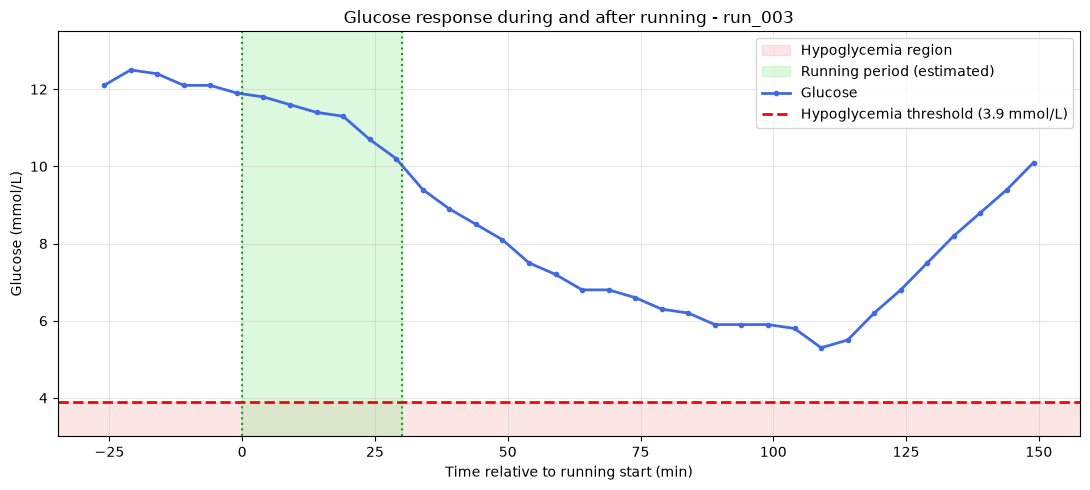

In [19]:
# Plot the first available running session
if not running_sessions.empty:
    session_id = running_sessions.iloc[0]["session_id"]

    plot_glucose_response(
        session_id,
        running_glucose,
        running_sessions
    )
else:
    print("No running sessions found.")

In [20]:
basal = preprocess_basal(participant_id, raw_dir)

print("Basal measurements:", len(basal))
print("Duplicate timestamps:", basal["basal_ts"].duplicated().sum())
print("Insulin kinds:", basal["insulin_kind"].unique())

display(basal.head(10))

Basal measurements: 10993
Duplicate timestamps: 20
Insulin kinds: <ArrowStringArray>
['R']
Length: 1, dtype: str


,basal_ts,basal_dose,insulin_kind
0,2023-11-10 00:00:00,1.725,R
1,2023-11-10 00:00:00,1.424,R
2,2023-11-10 00:05:00,1.439,R
3,2023-11-10 00:10:00,1.486,R
4,2023-11-10 00:15:00,1.768,R
5,2023-11-10 00:20:00,1.504,R
6,2023-11-10 00:25:00,1.531,R
7,2023-11-10 00:30:00,1.807,R
8,2023-11-10 00:35:00,1.524,R
9,2023-11-10 00:40:00,1.544,R


In [21]:
# Process bolus insulin
bolus = preprocess_bolus(participant_id, raw_dir)

print("Bolus measurements:", len(bolus))
print("Duplicate timestamps:", bolus["bolus_ts"].duplicated().sum())

display(bolus.head(10))

Bolus measurements: 677
Duplicate timestamps: 65


,bolus_ts,bolus_dose
0,2023-11-10 12:43:00,2.360
1,2023-11-10 14:27:00,0.239
2,2023-11-10 15:32:00,0.408
3,2023-11-10 16:52:00,0.340
4,2023-11-10 17:28:00,0.220
5,2023-11-10 18:10:00,0.430
6,2023-11-10 19:13:00,0.202
7,2023-11-10 19:46:00,1.360
8,2023-11-10 19:54:00,0.000
9,2023-11-10 19:54:00,3.270


In [22]:
# Link insulin to running sessions
running_insulin = link_insulin_to_running(
    basal,
    bolus,
    running_sessions
)

print("Linked insulin measurements:", len(running_insulin))
print("Running sessions with insulin data:",
      running_insulin["session_id"].nunique())

display(running_insulin.head(20))

Linked insulin measurements: 417
Running sessions with insulin data: 11


,insulin_ts,insulin_value,insulin_kind,insulin_type,session_id,time_from_start_min
0,2023-11-20 14:00:00,0.750,R,basal,run_003,-240.0
1,2023-11-20 14:05:00,0.780,R,basal,run_003,-235.0
2,2023-11-20 16:01:00,0.780,R,basal,run_003,-119.0
3,2023-11-20 16:06:00,0.600,R,basal,run_003,-114.0
4,2023-11-20 16:36:00,0.628,R,basal,run_003,-84.0
5,2023-11-20 16:41:00,0.600,R,basal,run_003,-79.0
6,2023-11-20 16:56:00,0.892,R,basal,run_003,-64.0
7,2023-11-20 17:01:00,1.056,R,basal,run_003,-59.0
8,2023-11-20 17:06:00,1.036,R,basal,run_003,-54.0
9,2023-11-20 17:11:00,1.545,R,basal,run_003,-49.0


In [23]:
# Process carbohydrate data
carbs = preprocess_carbs(participant_id, raw_dir)

# Link carbohydrates to running sessions
running_carbs = link_carbs_to_running(carbs, running_sessions)

print("Total carbohydrate registrations:", len(carbs))
print("Linked carbohydrate registrations:", len(running_carbs))

display(running_carbs.head(10))

Total carbohydrate registrations: 302
Linked carbohydrate registrations: 16


,meal_ts,carbs_g,session_id,time_from_start_min
0,2023-11-20 19:22:00,47.0,run_003,82.0
1,2023-11-27 19:17:00,98.0,run_005,77.0
2,2023-11-30 19:20:00,68.0,run_007,95.0
3,2023-12-05 19:11:00,41.0,run_013,86.0
4,2023-12-11 19:20:00,98.0,run_016,95.0
5,2023-12-17 14:26:00,28.5,run_017,-184.0
6,2023-12-17 18:55:00,98.0,run_017,85.0
7,2023-12-19 15:09:00,27.0,run_020,-171.0
8,2023-12-19 19:15:00,95.0,run_020,75.0
9,2023-12-29 17:04:00,11.0,run_023,-71.0


In [24]:
# Select the first running session automatically
session_id = running_sessions.iloc[0]["session_id"]

# Select carbohydrate data for this session
session_carbs = running_carbs[
    running_carbs["session_id"] == session_id
]

# Display results
print(f"Carbohydrate data for {session_id}")
print("Number of registrations:", len(session_carbs))
print("Total carbohydrates (g):", session_carbs["carbs_g"].sum(min_count=1))

display(session_carbs)

Carbohydrate data for run_003
Number of registrations: 1
Total carbohydrates (g): 47.0


,meal_ts,carbs_g,session_id,time_from_start_min
0,2023-11-20 19:22:00,47.0,run_003,82.0


### first 3 runs voor alfa

In [39]:
import pandas as pd

first_3_runs = running_sessions.head(3)

all_runs = []

for _, session in first_3_runs.iterrows():

    session_id = session["session_id"]

    # Time window: 30 minutes before running + running + 120 minutes after
    start = session["start_time"] - pd.Timedelta(minutes=30)
    end = session["end_time"] + pd.Timedelta(minutes=120)

    # Create 1-minute timeline
    table = pd.DataFrame({
        "Date and time": pd.date_range(
            start=start,
            end=end,
            freq="1min"
        )
    })


    # Time relative to running start
    table["Time relative to running (min)"] = (
        table["Date and time"] - session["start_time"]
    ).dt.total_seconds() / 60


    # Running status
    table["Running"] = "No"

    table.loc[
        (table["Date and time"] >= session["start_time"]) &
        (table["Date and time"] <= session["end_time"]),
        "Running"
    ] = "Yes"


    # -----------------------------
    # MET values
    # Only at actual measurement times
    # -----------------------------
    table["MET"] = None

    met_run = running_met[
        running_met["session_id"] == session_id
    ]

    for _, row in met_run.iterrows():

        exact_time = (
            table["Date and time"] == row["activity_ts"]
        )

        table.loc[exact_time, "MET"] = row["met"]


    # -----------------------------
    # Glucose values
    # Only at actual CGM measurement times
    # -----------------------------
    glucose_run = running_glucose[
        running_glucose["session_id"] == session_id
    ][
        ["bg_ts", "value"]
    ]

    table = table.merge(
        glucose_run,
        left_on="Date and time",
        right_on="bg_ts",
        how="left"
    )

    table = table.rename(
        columns={
            "value": "Glucose (mmol/L)"
        }
    )

    table = table.drop(
        columns=["bg_ts"]
    )


    # -----------------------------
    # Insulin values
    # Separate basal and bolus
    # Only at actual administration times
    # -----------------------------
    table["Basal insulin"] = None
    table["Bolus insulin"] = None

    insulin_run = running_insulin[
        running_insulin["session_id"] == session_id
    ]

    for _, row in insulin_run.iterrows():

        exact_time = (
            table["Date and time"] == row["insulin_ts"]
        )

        if row["insulin_type"] == "basal":
            table.loc[exact_time, "Basal insulin"] = row["insulin_value"]

        elif row["insulin_type"] == "bolus":
            table.loc[exact_time, "Bolus insulin"] = row["insulin_value"]


    # -----------------------------
    # Carbohydrate intake
    # Only at actual intake times
    # -----------------------------
    table["Carbohydrates (g)"] = None

    carbs_run = running_carbs[
        running_carbs["session_id"] == session_id
    ]

    for _, row in carbs_run.iterrows():

        exact_time = (
            table["Date and time"] == row["meal_ts"]
        )

        table.loc[exact_time, "Carbohydrates (g)"] = row["carbs_g"]


    # Add session ID
    table["Session"] = session_id

    all_runs.append(table)



# Show full tables
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)


for i, run_table in enumerate(all_runs):

    # Show missing values as "-"
    display_table = run_table.fillna("-")

    print(f"RUN {i+1}: {display_table['Session'].iloc[0]}")

    display(
        display_table[
            [
                "Date and time",
                "Time relative to running (min)",
                "Running",
                "MET",
                "Glucose (mmol/L)",
                "Basal insulin",
                "Bolus insulin",
                "Carbohydrates (g)"
            ]
        ]
    )

RUN 1: run_003


,Date and time,Time relative to running (min),Running,MET,Glucose (mmol/L),Basal insulin,Bolus insulin,Carbohydrates (g)
0,2023-11-20 17:30:00,-30.0,No,1.075988,-,-,-,-
1,2023-11-20 17:31:00,-29.0,No,-,-,1.877,-,-
2,2023-11-20 17:32:00,-28.0,No,-,-,-,-,-
3,2023-11-20 17:33:00,-27.0,No,-,-,-,-,-
4,2023-11-20 17:34:00,-26.0,No,-,12.1,-,-,-
5,2023-11-20 17:35:00,-25.0,No,-,-,-,-,-
6,2023-11-20 17:36:00,-24.0,No,-,-,1.715,-,-
7,2023-11-20 17:37:00,-23.0,No,-,-,-,-,-
8,2023-11-20 17:38:00,-22.0,No,-,-,-,-,-
9,2023-11-20 17:39:00,-21.0,No,-,12.5,-,-,-


RUN 2: run_005


,Date and time,Time relative to running (min),Running,MET,Glucose (mmol/L),Basal insulin,Bolus insulin,Carbohydrates (g)
0,2023-11-27 17:30:00,-30.0,No,1.0,-,-,-,-
1,2023-11-27 17:31:00,-29.0,No,-,-,-,-,-
2,2023-11-27 17:32:00,-28.0,No,-,-,-,-,-
3,2023-11-27 17:33:00,-27.0,No,-,-,0.54,-,-
4,2023-11-27 17:34:00,-26.0,No,-,7.0,-,-,-
5,2023-11-27 17:35:00,-25.0,No,-,-,-,-,-
6,2023-11-27 17:36:00,-24.0,No,-,-,-,-,-
7,2023-11-27 17:37:00,-23.0,No,-,-,-,-,-
8,2023-11-27 17:38:00,-22.0,No,-,-,0.485,-,-
9,2023-11-27 17:39:00,-21.0,No,-,6.7,-,-,-


RUN 3: run_007


,Date and time,Time relative to running (min),Running,MET,Glucose (mmol/L),Basal insulin,Bolus insulin,Carbohydrates (g)
0,2023-11-30 17:15:00,-30.0,No,1.0,-,-,-,-
1,2023-11-30 17:16:00,-29.0,No,-,-,0.686,-,-
2,2023-11-30 17:17:00,-28.0,No,-,-,-,-,-
3,2023-11-30 17:18:00,-27.0,No,-,-,-,-,-
4,2023-11-30 17:19:00,-26.0,No,-,9.4,-,-,-
5,2023-11-30 17:20:00,-25.0,No,-,-,-,-,-
6,2023-11-30 17:21:00,-24.0,No,-,-,0.6,-,-
7,2023-11-30 17:22:00,-23.0,No,-,-,-,-,-
8,2023-11-30 17:23:00,-22.0,No,-,-,-,-,-
9,2023-11-30 17:24:00,-21.0,No,-,9.3,-,-,-


RUN 1: run_003


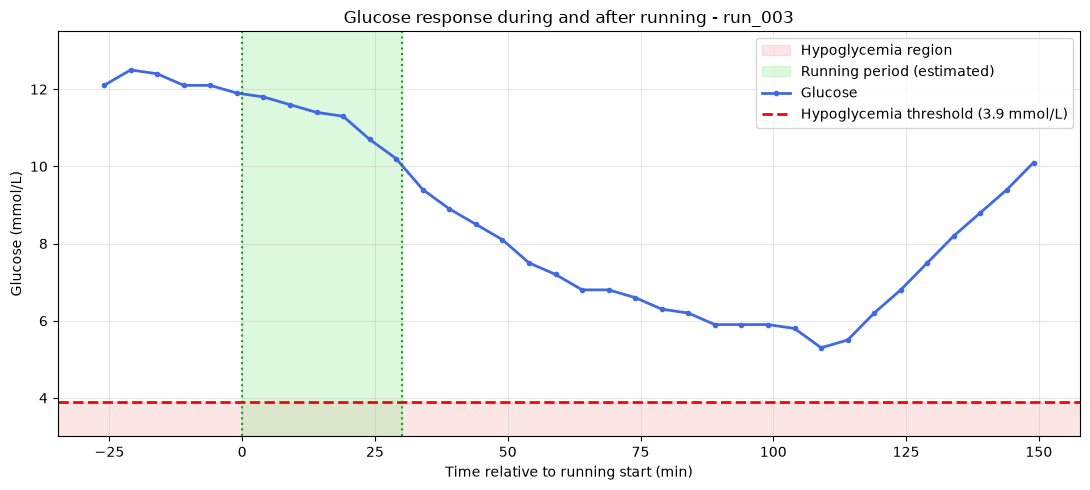

RUN 2: run_005


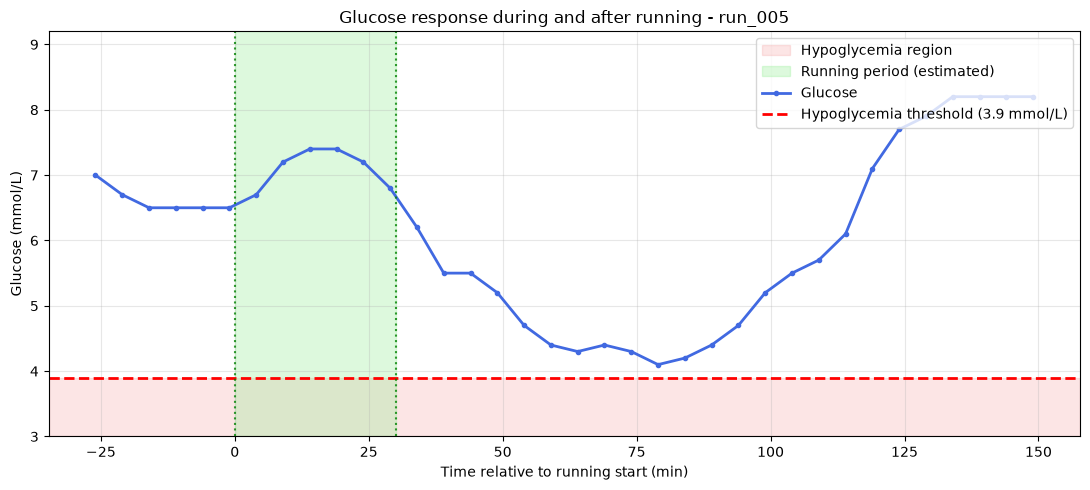

RUN 3: run_007


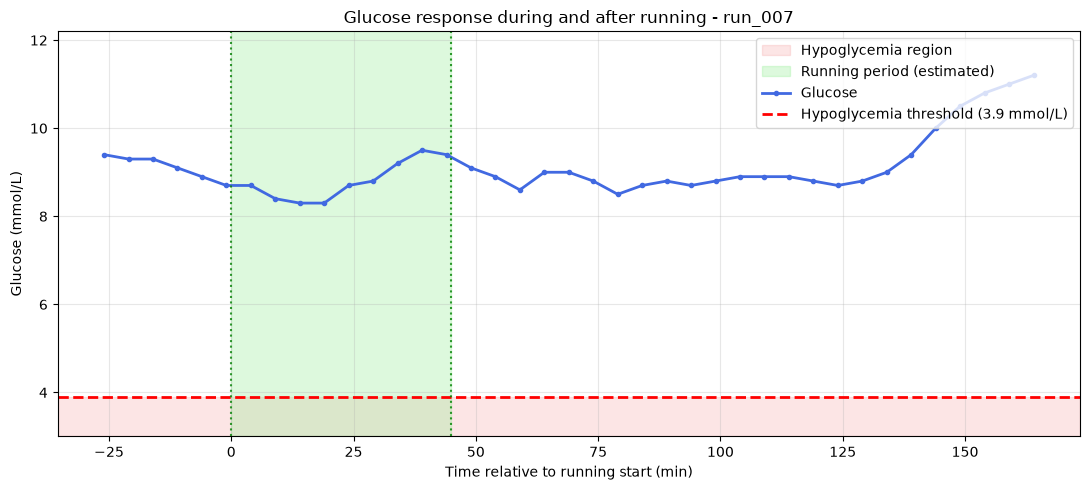

In [41]:
# Plot glucose response
first_3_runs = running_sessions.head(3)

for i, session in first_3_runs.iterrows():

    session_id = session["session_id"]

    print(f"RUN {i+1}: {session_id}")

    plot_glucose_response(
        session_id,
        running_glucose,
        running_sessions
    )